In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
### Load The Dataset
---

In [58]:
df = pd.read_csv("Student_Performance.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [59]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


---
### Identify The Number Of Rows And Columns
---

In [60]:
print("Number of rows: ",df.shape[0])
print("Number of columns: ",df.shape[1])

Number of rows:  10000
Number of columns:  6


In [61]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Hours Studied', 'Previous Scores', 'Extracurricular Activities', 'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index']


---
### Analyze The Dataset Structure And Datatypes

---

In [62]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        10000 non-null  str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  10000 non-null  int64  
 5   Performance Index                 10000 non-null  float64
dtypes: float64(1), int64(4), str(1)
memory usage: 493.2 KB


In [63]:
print("Data types of each column:")
print(df.dtypes)

Data types of each column:
Hours Studied                         int64
Previous Scores                       int64
Extracurricular Activities              str
Sleep Hours                           int64
Sample Question Papers Practiced      int64
Performance Index                   float64
dtype: object


In [64]:
print("Statistical summary:")
print(df.describe())

Statistical summary:
       Hours Studied  Previous Scores   Sleep Hours  \
count   10000.000000     10000.000000  10000.000000   
mean        4.992900        69.445700      6.530600   
std         2.589309        17.343152      1.695863   
min         1.000000        40.000000      4.000000   
25%         3.000000        54.000000      5.000000   
50%         5.000000        69.000000      7.000000   
75%         7.000000        85.000000      8.000000   
max         9.000000        99.000000      9.000000   

       Sample Question Papers Practiced  Performance Index  
count                      10000.000000       10000.000000  
mean                           4.583300          55.224800  
std                            2.867348          19.212558  
min                            0.000000          10.000000  
25%                            2.000000          40.000000  
50%                            5.000000          55.000000  
75%                            7.000000          71.0000

---
### Check For Missing Values
---

In [65]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64


In [66]:
print("Total missing values:")
print(df.isnull().sum().sum())

Total missing values:
0


---
### Identify And Remove Duplicates
---

In [67]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 127


In [68]:
df = df.drop_duplicates()

In [69]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


---
### Perform Basic Data Cleaning
---

In [70]:
df_clean = df.copy()

In [71]:
numeric_cols = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(
        df_clean[col], errors="coerce"
    )

In [72]:
df_clean.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


In [73]:
# Scores must be between 0 and 100
for col in ["Previous Scores", "Performance Index"]:
    df_clean.loc[
        (df_clean[col] < 0) | (df_clean[col] > 100),
        col
    ] = np.nan

# Study & Sleep hours cannot be negative
for col in ["Sleep Hours", "Hours Studied"]:
    df_clean.loc[df_clean[col] < 0, col] = np.nan

# Sample Papers cannot be negative
df_clean.loc[df_clean["Sample Question Papers Practiced"] < 0, "Sample Question Papers Practiced"] = np.nan


In [74]:
df_clean.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7.0,99.0,Yes,9.0,1.0,91.0
1,4.0,82.0,No,4.0,2.0,65.0
2,8.0,51.0,Yes,7.0,2.0,45.0
3,5.0,52.0,Yes,5.0,2.0,36.0
4,7.0,75.0,No,8.0,5.0,66.0


In [75]:
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

In [76]:
categorical_cols = [
    "Extracurricular Activities"
]

for col in categorical_cols:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace("", pd.NA)

    if df_clean[col].notna().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode().iloc[0]
        )
    else:
        df_clean[col] = df_clean[col].fillna("Unknown")

In [77]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum())
print("\nDuplicate rows:", df_clean.duplicated().sum())
print("\nCleaned dataset shape:", df_clean.shape)

Missing values after cleaning:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

Duplicate rows: 0

Cleaned dataset shape: (9873, 6)


---
### Generate Basic Statistical Insights
---

In [78]:
print("Statistical summary:")
print(df_clean.describe().T)

Statistical summary:
                                   count       mean        std   min   25%  \
Hours Studied                     9873.0   4.992100   2.589081   1.0   3.0   
Previous Scores                   9873.0  69.441102  17.325601  40.0  54.0   
Sleep Hours                       9873.0   6.531652   1.697683   4.0   5.0   
Sample Question Papers Practiced  9873.0   4.583004   2.867202   0.0   2.0   
Performance Index                 9873.0  55.216651  19.208570  10.0  40.0   

                                   50%   75%    max  
Hours Studied                      5.0   7.0    9.0  
Previous Scores                   69.0  85.0   99.0  
Sleep Hours                        7.0   8.0    9.0  
Sample Question Papers Practiced   5.0   7.0    9.0  
Performance Index                 55.0  70.0  100.0  


---
### Create Data Visualizations
---

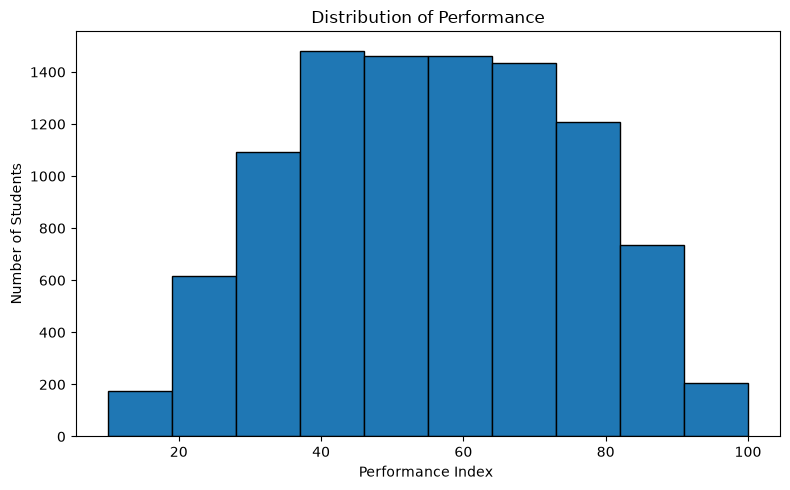

In [79]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["Performance Index"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Performance")
plt.xlabel("Performance Index ")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.savefig("performance_index_distribution.png")
plt.show()

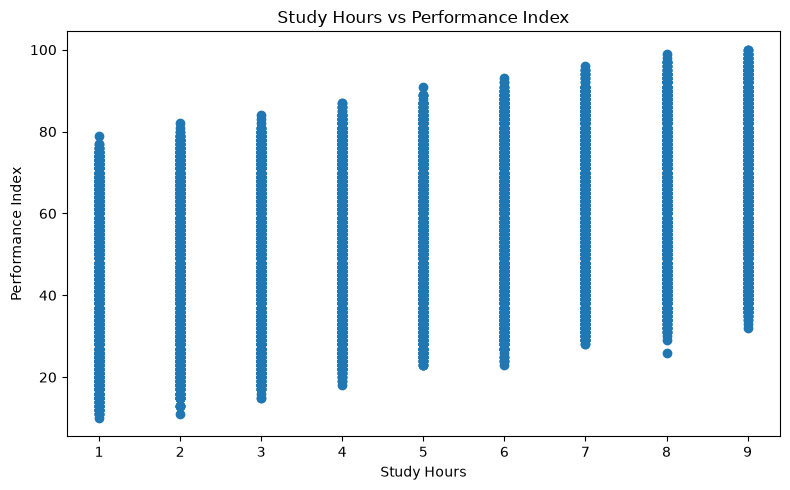

In [80]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Hours Studied"],
    df_clean["Performance Index"]
)

plt.title("Study Hours vs Performance Index")
plt.xlabel("Study Hours")
plt.ylabel("Performance Index")
plt.tight_layout()
plt.savefig("study_hours_vs_performance_index.png")
plt.show()

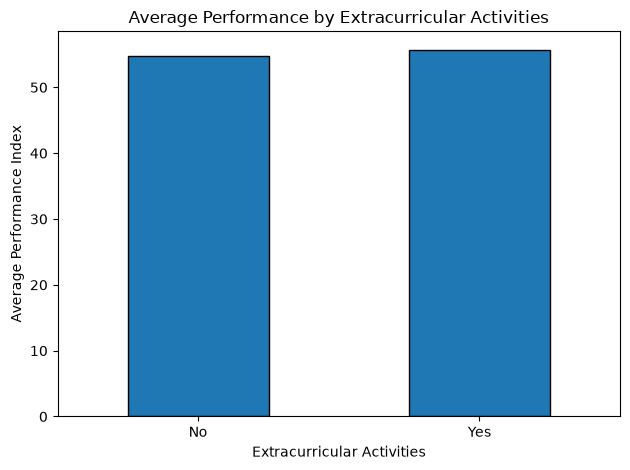

In [81]:
avg_performance = df.groupby(
    "Extracurricular Activities"
)["Performance Index"].mean()

avg_performance.plot(kind="bar", edgecolor="black")
plt.title("Average Performance by Extracurricular Activities")
plt.xlabel("Extracurricular Activities")
plt.ylabel("Average Performance Index")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("performance_index_vs_extracurricular_activities.png")
plt.show()

---
### Save Cleaned Dataset
---

In [82]:
df_clean.to_csv("student_performance_cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
